# #204 Track A Gate A v4 — data-build audit

This executed notebook constructs a bounded common M×3 development/test panel through the reusable adapter, then audits the authoritative immutable package. It reads no result, final-SP target, settlement, payout, or ROI field.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
PACKAGE = ROOT / 'results/bj204_gate_a_preoutcome_v4'
SOURCE = ROOT / 'results/bj203_causal_tensor_v2'
FIXTURES = ROOT / 'tests/fixtures/bj204'
assert PACKAGE.is_dir() and SOURCE.is_dir() and FIXTURES.is_dir()
print('canonical package:', PACKAGE.name)

canonical package: bj204_gate_a_preoutcome_v4


In [2]:
from unified_model.gate_a import verify_package

verification = verify_package(PACKAGE)
card = json.loads((PACKAGE / 'freeze_card.json').read_text())
source_inventory = pd.DataFrame([{'name': k, 'value': v} for k, v in card['source'].items() if k.endswith('sha256') or k.endswith('source')])
assert card['source']['labels_opened'] is False
display(source_inventory)
verification

,name,value
0,history_proxy_sha256,867e11452306c29e7b64b97af82f730ab0d96f7519d995...
1,history_proxy_source,data/beidan_history.db
2,inference_manifest_sha256,c915c6e628b4ebfe389ab31fd3709561440892ede711f2...
3,official_3sp_identity_sha256,e7256d96a34c2f41ede349c87b9cd1efc7a61b104657a6...
4,official_3sp_identity_source,data/raw/beidan_full_3sp.csv
5,p_close_bridge_sha256,48d73b868235a78d73ea2587d5a2cd9094a861b605bfcd...
6,p_close_bridge_source,data/beidan_features.db


{'contract_version': 'bj204-market-anchored-model-gate-a-v4',
 'files': 22,
 'status': 'PASS'}

In [3]:
splits = pd.read_csv(PACKAGE / 'split_manifest.csv', dtype={'issue': str})
yearly = splits.loc[splits.role.eq('DEVELOPMENT_CV')].groupby('year').agg(issues=('issue', 'nunique'), matches=('issue_instance', 'size')).reset_index()
assert yearly.issues.tolist() == [55, 44, 58, 58, 55, 59, 15]
assert splits.loc[splits.role.eq('DEVELOPMENT_CV'), 'issue'].nunique() == 344
assert splits.loc[splits.role.eq('RETROSPECTIVE_TEST_LOCKED'), 'issue'].nunique() == 75
yearly

,year,issues,matches
0,2019,55,55
1,2020,44,44
2,2021,58,58
3,2022,58,58
4,2023,55,55
5,2024,59,59
6,2025,15,15


In [4]:
test_identity = pd.read_csv(PACKAGE / 'test_identity_reconciliation.csv', dtype={'issue': str})
dev_target_identity = pd.read_csv(PACKAGE / 'development_target_identity_reconciliation.csv', dtype={'issue': str})
duplicate_resolution = pd.read_csv(PACKAGE / 'pclose_duplicate_resolution.csv')
reconciliation = pd.DataFrame([
    {'scope': 'locked test identity', 'rows': len(test_identity), 'matched': int(test_identity.official_target_identity_available.sum()), 'unmatched': int((~test_identity.official_target_identity_available).sum())},
    {'scope': '25041/25042 development identity', 'rows': len(dev_target_identity), 'matched': int(dev_target_identity.official_target_identity_available.sum()), 'unmatched': int((~dev_target_identity.official_target_identity_available).sum())},
    {'scope': 'p_close duplicate match_uid keys', 'rows': len(duplicate_resolution), 'matched': 0, 'unmatched': 0},
])
assert reconciliation.loc[0, 'rows'] == 16990 and reconciliation.loc[0, 'matched'] == 16853
assert reconciliation.loc[1, 'rows'] == 1024 and reconciliation.loc[1, 'matched'] == 1021
reconciliation

,scope,rows,matched,unmatched
0,locked test identity,16990,16853,137
1,25041/25042 development identity,1024,1021,3
2,p_close duplicate match_uid keys,3,0,0


In [5]:
from unified_model.gate_a import _common_adapter, _read_full_3sp_identity, _read_history_rows, _validate_source

identity, _ = _validate_source(SOURCE)
fixture_dev = identity.loc[identity.issue.astype(str).eq('190101') & identity.match_idx.isin([1, 2])].copy()
fixture_test = _read_history_rows(FIXTURES / 'history_proxy.csv', ((25043, 25043),))
fixture_full = _read_full_3sp_identity(FIXTURES / 'full_3sp_identity.csv')
fixture_features, fixture_masks, fixture_registry, fixture_coverage, fixture_duplicates = _common_adapter(
    SOURCE, fixture_dev, fixture_test, fixture_full, FIXTURES / 'pclose_proxy.csv', strict_census=False
)
assert fixture_features.groupby(['issue', 'match_idx']).size().eq(3).all()
fixture_coverage

,role,source_grade,year,issues,matches,complete_market_rows,common_schema_coverage
0,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,1,2,2,1.0
1,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2025,1,2,2,1.0


In [6]:
from unified_model.gate_a import load_common_issue

dev_values, dev_masks, names = load_common_issue(PACKAGE, '190101')
test_values, test_masks, test_names = load_common_issue(PACKAGE, '25043')
assert names == test_names and dev_values.shape[1:] == test_values.shape[1:] == (3, len(names))
pd.DataFrame([
    {'split': 'development', 'shape': dev_values.shape, 'mask_true_rate': float(dev_masks.mean()), 'source_grade': 'RETROSPECTIVE_PROXY_PCLOSE'},
    {'split': 'locked test', 'shape': test_values.shape, 'mask_true_rate': float(test_masks.mean()), 'source_grade': 'RETROSPECTIVE_PROXY'},
])

,split,shape,mask_true_rate,source_grade
0,development,"(182, 3, 6)",0.831502,RETROSPECTIVE_PROXY_PCLOSE
1,locked test,"(493, 3, 6)",0.833333,RETROSPECTIVE_PROXY


In [7]:
common_cell_features = pd.read_parquet(PACKAGE / 'common_cell_features.parquet')
coverage = pd.read_csv(PACKAGE / 'common_schema_coverage_by_period.csv')
field_coverage = pd.read_csv(PACKAGE / 'common_schema_field_coverage.csv')
assert len(common_cell_features) == 3 * (102245 + 16990)
assert coverage.matches.sum() == 102245 + 16990
assert field_coverage.outcome_code.astype(str).isin(['0', '1', '3']).all()
display(coverage)
field_coverage.groupby(['role', 'feature'], sort=True).agg(cells=('cells', 'sum'), available=('available_cells', 'sum')).assign(coverage=lambda x: x.available / x.cells).reset_index()

,role,source_grade,year,issues,matches,complete_market_rows,common_schema_coverage
0,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,55,17694,17565,0.992709
1,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2020,44,12033,11815,0.981883
2,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2021,58,18881,18624,0.986388
3,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2022,58,16787,16579,0.987609
4,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2023,55,15759,15595,0.989593
5,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2024,59,16236,16057,0.988975
6,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2025,15,4855,4794,0.987436
7,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2025,42,11382,11366,0.998594
8,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,33,5608,5602,0.998930


,role,feature,cells,available,coverage
0,DEVELOPMENT_CV,market_probability,306735,303087,0.988107
1,DEVELOPMENT_CV,market_proxy_complete,306735,306735,1.000000
2,DEVELOPMENT_CV,native_handicap_line,306735,303108,0.988175
3,DEVELOPMENT_CV,predicted_final_sp_input,306735,23520,0.076679
4,DEVELOPMENT_CV,source_is_average_eu,306735,306735,1.000000
5,DEVELOPMENT_CV,source_is_pclose,306735,306735,1.000000
6,RETROSPECTIVE_TEST_LOCKED,market_probability,50970,50904,0.998705
7,RETROSPECTIVE_TEST_LOCKED,market_proxy_complete,50970,50970,1.000000
8,RETROSPECTIVE_TEST_LOCKED,native_handicap_line,50970,50970,1.000000
9,RETROSPECTIVE_TEST_LOCKED,predicted_final_sp_input,50970,0,0.000000


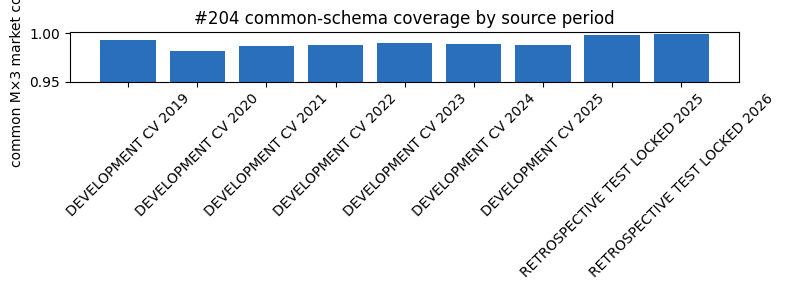

In [8]:
plot = coverage.assign(period=lambda x: x.role.str.replace('_', ' ') + ' ' + x.year.astype(str))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(plot.period, plot.common_schema_coverage, color=['#2a6fbb'] * len(plot))
ax.set_ylim(0.95, 1.001); ax.set_ylabel('common M×3 market coverage'); ax.tick_params(axis='x', rotation=45)
ax.set_title('#204 common-schema coverage by source period')
fig.tight_layout()
plt.show()

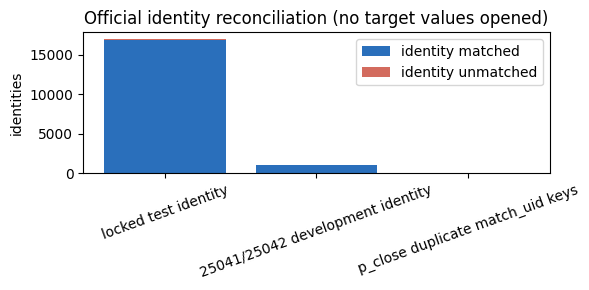

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(reconciliation.scope, reconciliation.matched, label='identity matched', color='#2a6fbb')
ax.bar(reconciliation.scope, reconciliation.unmatched, bottom=reconciliation.matched, label='identity unmatched', color='#d36b5e')
ax.tick_params(axis='x', rotation=20); ax.set_ylabel('identities'); ax.set_title('Official identity reconciliation (no target values opened)')
ax.legend(); fig.tight_layout(); plt.show()

In [10]:
schema = json.loads((PACKAGE / 'inference_schema.json').read_text())
assert schema['sp_target']['field'] == 'final_sp'
assert 'final_sp' not in schema['model_features']
assert schema['predicted_final_sp_semantics'] == 'outcome-unexposed pre-event proxy input only'
print('Target remains unopened:', schema['sp_target']['quality_mask'])

Target remains unopened: TARGET_ONLY_OFFICIAL_3SP_NOT_OPENED_GATE_A
